# Area summaries {#sec-areas}

:::{.aside}
Our setup for this R session is: 

In [1]:
#| warnings: false
#| message: false
library(sf)
library(ecoSynthesis)
library(dplyr)
library(units)
library(ggplot2)
library(tidyr)

Linking to GEOS 3.13.0, GDAL 3.8.5, PROJ 9.5.1; sf_use_s2() is TRUE


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


udunits database from /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/library/units/share/udunits/udunits2.xml



In [2]:
here::i_am("synthesis/EFG-map.qmd")
output_dir <- here::here("output-XREFs")
source(here::here("inc/setup.R"))
load(here::here(output_dir, "lookup-tables.rda"))
load(here::here(output_dir, "memb-summaries.rda"))

here() starts at /Users/z3529065/proyectos/EIW/TASVEG-XREF



:::

## Summarising areas

We read the spatial data from the TASVEG dataset using `read_sf` from the `sf` package.

We then use the `st_area` to calculate the spatial extent of each spatial feature.For the next calculation we don't need to keep the spatial information, so we use  but we drop the geometry column to speed up other calculations.  

In [3]:
TASVEG_xy <- read_sf(here::here("gisdata","TASVEG_5_0.shp")) |>
    select(VEG_GROUP, VEGCODE, VEGCODE_D)
TASVEG_areas <- TASVEG_xy |> 
    mutate(area = st_area(geometry)) |> 
    st_drop_geometry()

We have four different membership summary tables created in @sec-synthesis. Each one of these approaches will lead to different interpretation of spatial data linked to the source concepts and their mapping units.

### Weighted area estimates

For calculations of areas we have to consider that each source unit might be represented by multiple map units, and each map unit might be assigned to more that one target unit.

The calculations in this workflow assume that the relationships between source and target units are the same for all mapping unit within each source unit. 

This can be calculated using a left join of both tables with a `many to many` relationship:

In [4]:
EFG_memb_exp_areas <- TASVEG_areas |>
    left_join(TASVEG_revised, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) 

Furthermore, we need to decide if we want to adjust the areas to represent uncertainty in the assignment of the relationship. One possible way to adjust the areas is to use the membership value as an estimate of the proportion of the area that can be assigned to the target unit.

Using an example of one target unit (T2.5), we can summarise the data by expert and membership and calculate total areas of the units vs the weighed area estimates:

In [5]:
 EFG_memb_exp_areas |>
    filter(EFG == "T2.5") |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * memb),'km2') ,
          .by=c(expert, EFG, best)) |>
    filter(!is.na(area_total))

expert,EFG,best,nr_VEGCODE,mean_memb,area_total,area_weighted
<chr>,<chr>,<lgl>,<int>,<dbl>,<[km^2]>,<[km^2]>
Anne Kitchener,T2.5,TRUE,24,0.9692852,12729.991 [km^2],12381.1177 [km^2]
Adelina_Latinovic,T2.5,TRUE,24,0.9722410,12729.991 [km^2],12411.4079 [km^2]
David_Keith,T2.5,TRUE,26,0.7834967,13066.199 [km^2],10660.2603 [km^2]
Jayne_Balmer,T2.5,TRUE,22,0.9747669,12400.035 [km^2],12149.2128 [km^2]
Mark_Tozer,T2.5,TRUE,24,0.8511534,12808.832 [km^2],11287.2072 [km^2]
Anne Kitchener,T2.5,FALSE,6,0.3268494,2465.049 [km^2],824.7529 [km^2]
Adelina_Latinovic,T2.5,FALSE,7,0.3246059,2491.372 [km^2],827.3851 [km^2]
David_Keith,T2.5,FALSE,5,0.1037661,3728.546 [km^2],397.0298 [km^2]
Mark_Tozer,T2.5,FALSE,7,0.1314380,5812.323 [km^2],681.1592 [km^2]


Interpreters differ in the nr of source of unit and the mean membership values assigned to those units. Consequently the total and weighted area estimates will be different.

We need to reshape the data if we want to explore this at the level of the source units:

In [6]:

plot_data <- EFG_memb_exp_areas |>
    filter(EFG == "T2.5") |>
    summarise(
        total_area = sum(drop_units(area)), 
        .by = all_of(c("expert", "VEGCODE", "memb","best"))) |>
    mutate(
        sid = reorder(VEGCODE, total_area), 
        assigned_area = total_area*memb,
        remaining_area = total_area - assigned_area) |>
    pivot_longer(cols = c(assigned_area,remaining_area), 
        names_to = "segment", values_to = "height") |>
    mutate(segment = factor(segment, levels = c("remaining_area", "assigned_area")))  |>
    arrange(sid)


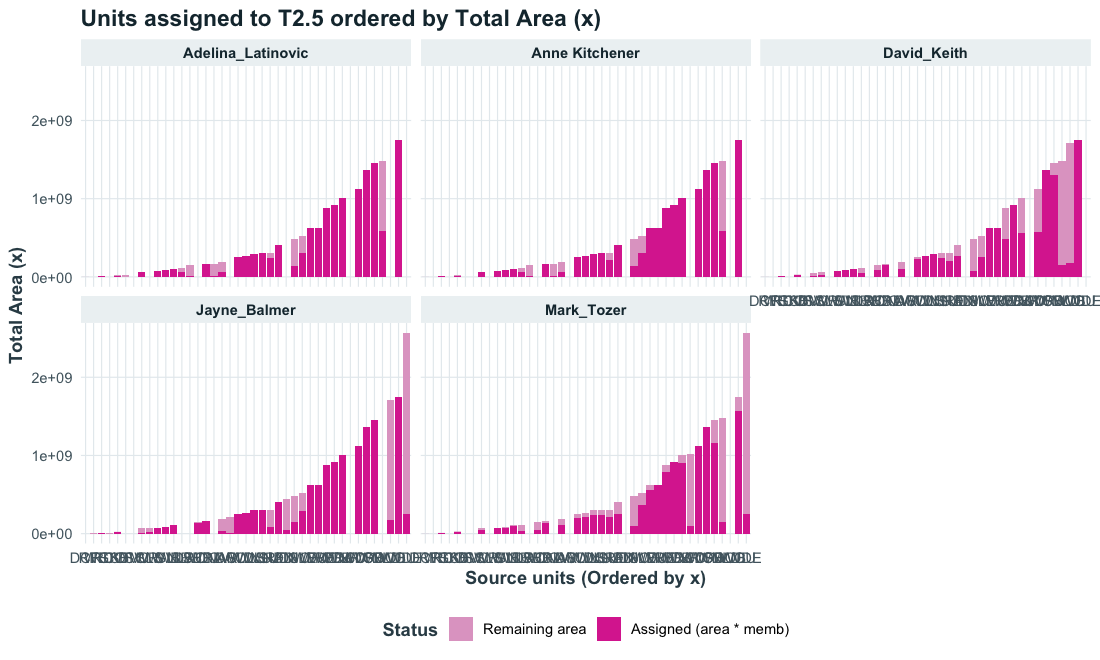

In [8]:

  ggplot(plot_data, aes(x=sid,y=height, fill=segment)) +
    geom_col(position = "stack") +
    scale_fill_manual(
    values = c("assigned_area" = "#db349e", "remaining_area" = "#e1a6cb"),
    labels = c("assigned_area" = "Assigned (area * memb)", "remaining_area" = "Remaining area")
    ) +
    labs(
      title = "Units assigned to T2.5 ordered by Total Area (x)",
      x = "Source units (Ordered by x)",
      y = "Total Area (x)",
      fill = "Status"
    ) +
    facet_wrap(~expert) + theme_wp3()
      

This plot reveals that some large units have low membership values, thus they contribute to larger total areas but only marginally to the weighted area estimates. 

We can choose to keep only the best candidate target unit for these area calculations

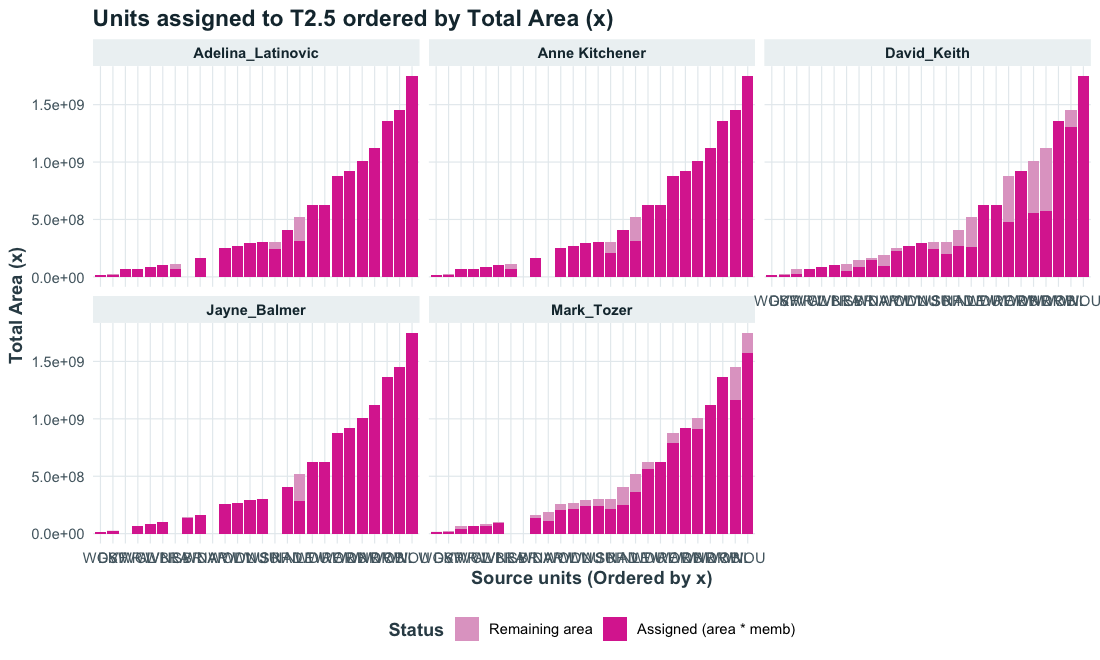

In [9]:
ggplot(filter(plot_data,best), aes(x=sid,y=height, fill=segment)) +
    geom_col(position = "stack") +
    scale_fill_manual(
    values = c("assigned_area" = "#db349e", "remaining_area" = "#e1a6cb"),
    labels = c("assigned_area" = "Assigned (area * memb)", "remaining_area" = "Remaining area")
    ) +
    labs(
      title = "Units assigned to T2.5 ordered by Total Area (x)",
      x = "Source units (Ordered by x)",
      y = "Total Area (x)",
      fill = "Status"
    ) +
    facet_wrap(~expert) + theme_wp3()

In [10]:

EFG_memb_agg_areas <- TASVEG_areas |>
    left_join(TASVEG_summary, by = "VEGCODE", relationship = "many-to-many") |> 
    mutate(EFG = coalesce(EFG,"!XREF")) 

In [ ]:
 EFG_memb_agg_areas |>
    filter(EFG == "T2.5") |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(prop_memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * prop_memb),'km2') ,
          .by=c(EFG, best)) |>
    filter(!is.na(area_total))

EFG,best,nr_VEGCODE,mean_memb,area_total,area_weighted
<chr>,<lgl>,<int>,<dbl>,<[km^2]>,<[km^2]>
T2.5,TRUE,24,0.9087368,12729.991 [km^2],11717.5989 [km^2]
T2.5,FALSE,17,0.1280118,8750.042 [km^2],764.0443 [km^2]


In [16]:
plot_data <- EFG_memb_agg_areas |>
    filter(EFG == "T2.5") |>
    summarise(
        total_area = sum(drop_units(area)), 
        .by = all_of(c("VEGCODE", "prop_memb","best"))) |>
    mutate(
        sid = reorder(VEGCODE, total_area), 
        assigned_area = total_area*prop_memb,
        remaining_area = total_area - assigned_area) |>
    pivot_longer(cols = c(assigned_area,remaining_area), 
        names_to = "segment", values_to = "height") |>
    mutate(segment = factor(segment, levels = c("remaining_area", "assigned_area")))  |>
    arrange(sid)

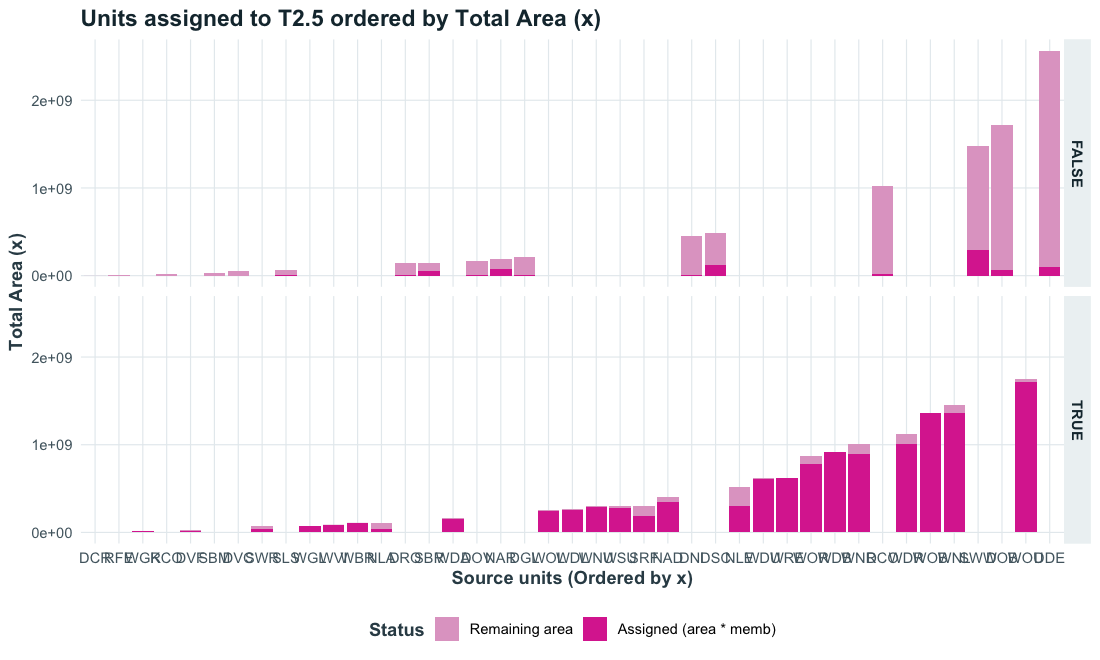

In [24]:
ggplot(filter(plot_data), aes(x=sid,y=height, fill=segment)) +
    geom_col(position = "stack") +
    scale_fill_manual(
    values = c("assigned_area" = "#db349e", "remaining_area" = "#e1a6cb"),
    labels = c("assigned_area" = "Assigned (area * memb)", "remaining_area" = "Remaining area")
    ) +
    labs(
      title = "Units assigned to T2.5 ordered by Total Area (x)",
      x = "Source units (Ordered by x)",
      y = "Total Area (x)",
      fill = "Status"
    ) +
    facet_grid(best~.) +
    theme_wp3()

In [35]:

d1 <- EFG_memb_exp_areas |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * memb),'km2') ,
          .by=c(expert, EFG, best)) |>
    filter(!is.na(area_total))

d2 <- EFG_memb_agg_areas |>
    summarise(
        nr_VEGCODE = n_distinct(VEGCODE),
        mean_memb = mean(prop_memb),
        area_total = set_units(sum(area),'km2') ,
        area_weighted = set_units(sum(area * prop_memb),'km2') ,
          .by=c(EFG, best)) |>
    filter(!is.na(area_total))

plot_data <- bind_rows(d1,d2)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


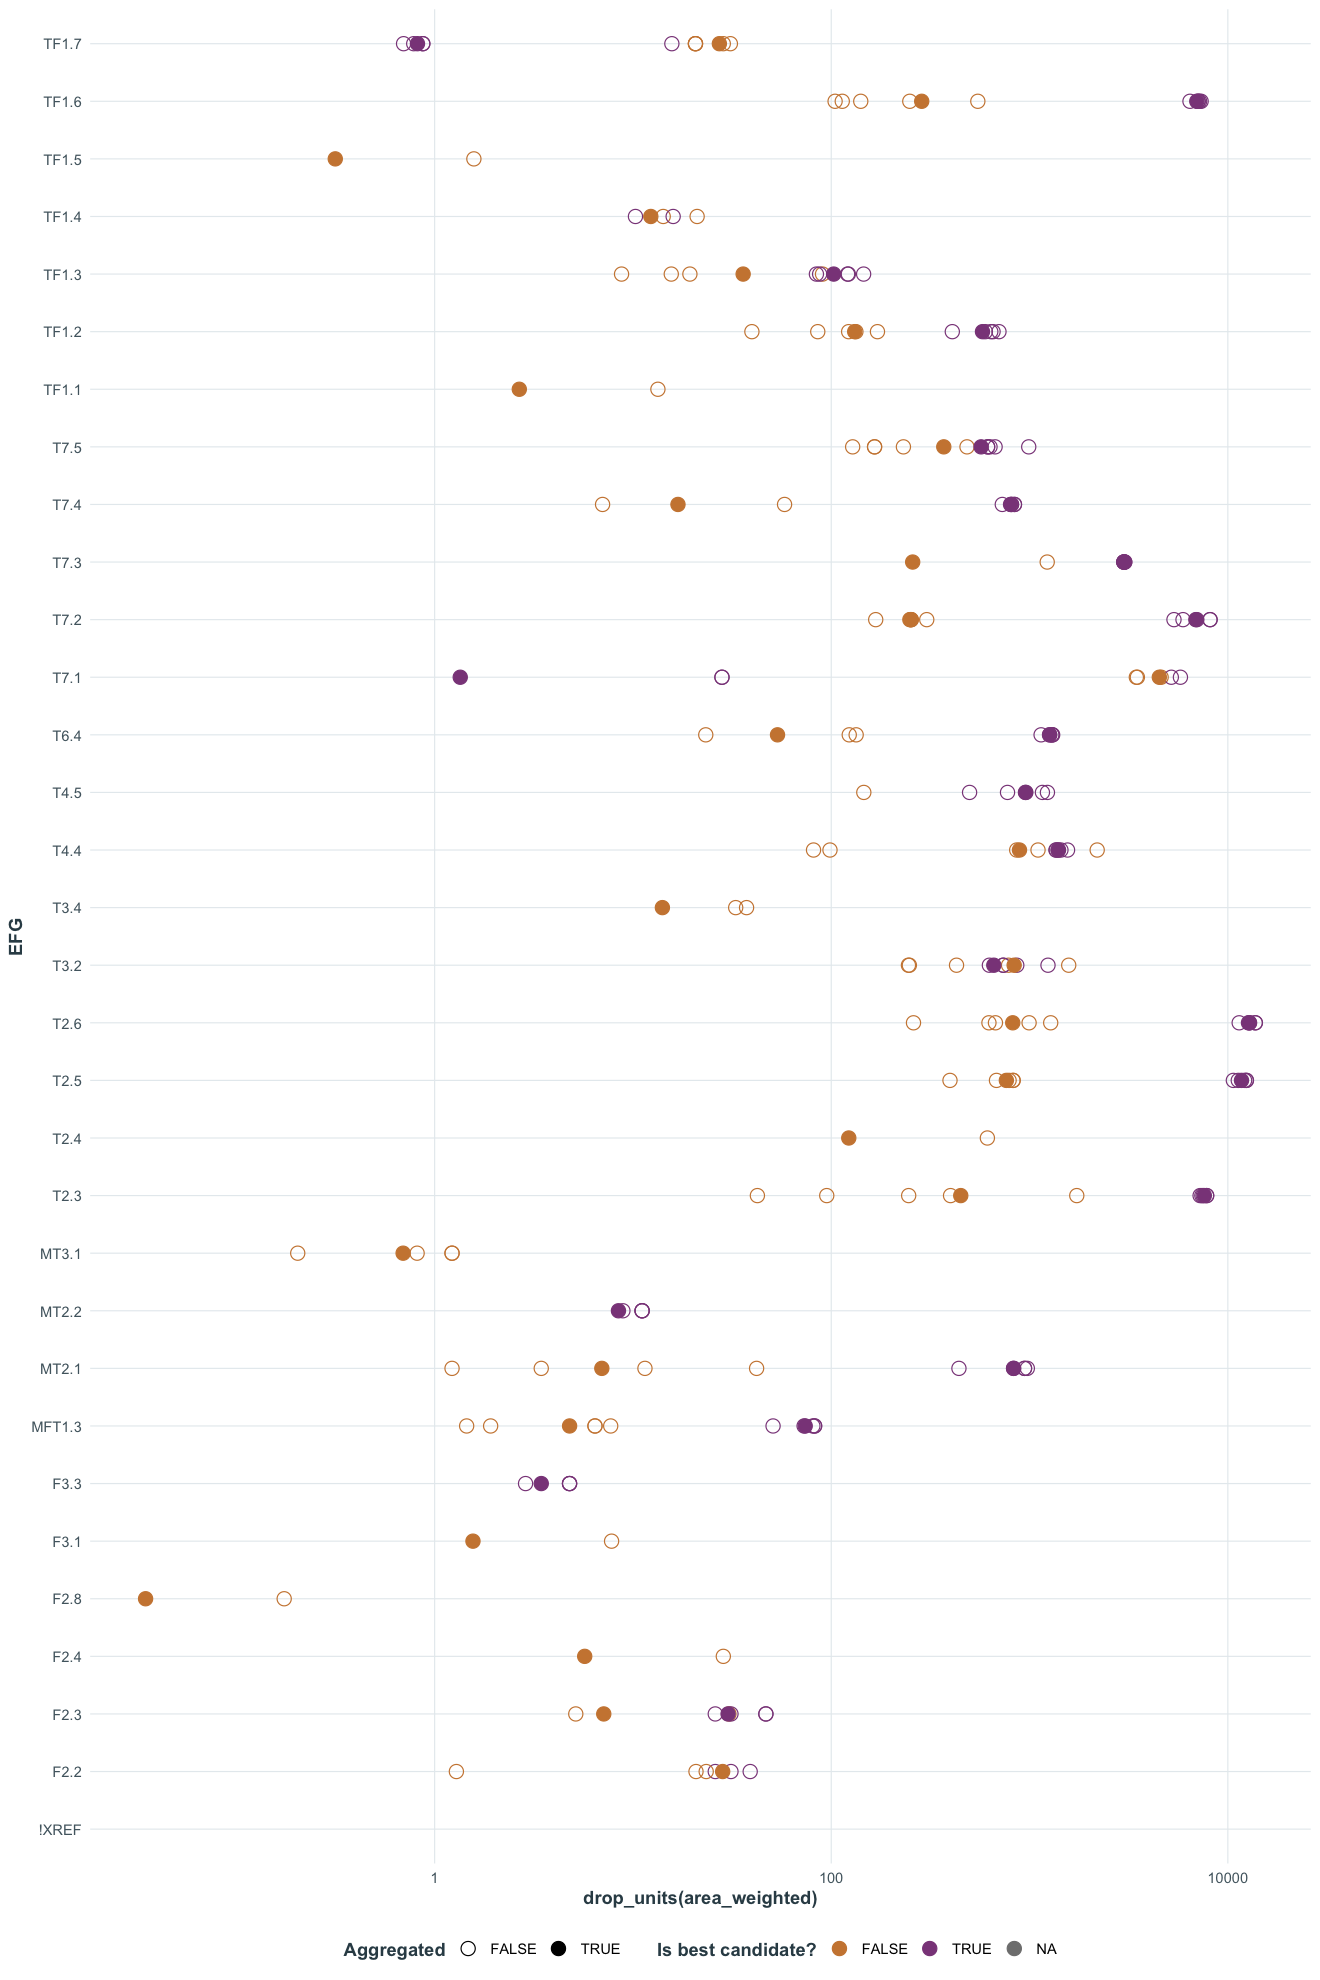

In [62]:
options(repr.plot.width = 12, repr.plot.height = 18)
ggplot(plot_data) +
geom_point(aes(y=EFG,x=drop_units(area_weighted), shape=is.na(expert), colour=best), size=4) +
scale_x_log10() +
scale_colour_manual(
    values = c("FALSE" = "peru", "TRUE"= "orchid4"), 
    na.value = "grey50",
    name = "Is best candidate?") +
  scale_shape_manual(
    values = c("TRUE" = 19, "FALSE"= 21), 
    name = "Aggregated") +
  theme_wp3()